In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/raw/India_house_detail.csv")

print("Shape:", df.shape)

df.head()

Shape: (260000, 57)


,property_id,listing_date,city,state,city_tier,locality,latitude,longitude,property_type,bhk,...,builder_reputation_score,seller_type,rera_registered,ownership_type,property_tax_annual_inr,maintenance_charges_monthly_inr,days_on_market,is_negotiable,price_inr,price_per_sqft
0,IN0000001,2024-06-20,Jodhpur,Rajasthan,2,Ashok Extension,26.21204,73.03690,Apartment,2,...,6.9,Agent,1,Leasehold,4538.0,4563.0,52,Yes,3807258.0,3458.0
1,IN0000002,2023-12-16,Indore,Madhya Pradesh,2,Hill Phase 1,22.77042,75.86870,Independent House,1,...,7.2,Owner,0,Co-operative Society,4134.0,2977.0,313,Yes,2278968.0,4236.0
2,IN0000003,2024-05-03,Nellore,Andhra Pradesh,3,New Nagar,14.49051,79.99337,Independent House,4,...,5.2,Builder,1,Leasehold,12927.0,5804.0,60,Yes,9655800.0,4598.0
3,IN0000004,2022-04-18,Amritsar,Punjab,2,Vidya Enclave,31.64208,74.75148,Apartment,2,...,6.6,Owner,1,Co-operative Society,5403.0,5364.0,29,Yes,5429476.0,5018.0
4,IN0000005,2023-08-23,Bangalore,Karnataka,1,Golden Extension,13.03995,77.53008,Penthouse,3,...,6.2,Owner,1,Freehold,10569.0,2312.0,54,No,25095400.0,18700.0


In [3]:
df.isna().sum() [df.isna().sum() > 0]

plot_area_sqft          164648
distance_to_metro_km    153652
dtype: int64

In [4]:
df.describe()

,city_tier,latitude,longitude,bhk,super_built_up_area_sqft,carpet_area_sqft,plot_area_sqft,bathrooms,balconies,floor_no,...,distance_to_mall_km,distance_to_it_hub_km,air_quality_index,builder_reputation_score,rera_registered,property_tax_annual_inr,maintenance_charges_monthly_inr,days_on_market,price_inr,price_per_sqft
count,260000.000000,260000.000000,260000.000000,260000.000000,260000.000000,260000.000000,95352.000000,260000.000000,260000.000000,260000.000000,...,260000.000000,260000.000000,260000.00000,260000.000000,260000.000000,260000.000000,260000.000000,260000.000000,2.600000e+05,260000.000000
mean,1.831227,21.027714,78.948749,2.585788,1296.287100,972.344038,2271.560544,2.615462,2.066000,10.253754,...,2.992774,6.993713,112.14190,6.483922,0.648438,7448.470408,4864.716027,182.697854,9.007761e+06,6940.114531
std,0.691880,6.020647,5.525138,0.990450,583.847564,441.818713,1143.014352,1.162751,1.064603,8.866980,...,2.950991,6.886471,41.79884,1.755596,0.477459,4284.343310,2860.849711,105.102554,8.144257e+06,4926.403022
min,1.000000,8.306360,70.589430,1.000000,280.000000,190.000000,309.000000,1.000000,0.000000,0.000000,...,0.100000,0.200000,25.00000,1.000000,0.000000,704.000000,425.000000,1.000000,4.167060e+05,1070.000000
25%,1.000000,17.346350,74.897560,2.000000,890.000000,664.000000,1458.000000,2.000000,1.000000,3.000000,...,0.900000,2.000000,82.00000,5.300000,0.000000,4322.000000,2762.000000,92.000000,4.195515e+06,3940.000000
50%,2.000000,22.270880,77.565300,2.000000,1202.000000,899.000000,2040.000000,3.000000,2.000000,8.000000,...,2.100000,4.900000,111.00000,6.500000,1.000000,6537.000000,4253.000000,183.000000,6.602186e+06,5402.000000
75%,2.000000,25.708375,80.914065,3.000000,1552.000000,1173.000000,2846.250000,3.000000,3.000000,16.000000,...,4.200000,9.700000,141.00000,7.700000,1.000000,9554.000000,6274.000000,274.000000,1.080481e+07,7990.000000
max,3.000000,32.978100,94.130530,5.000000,3549.000000,2886.000000,8428.000000,6.000000,4.000000,39.000000,...,18.000000,40.000000,299.00000,10.000000,1.000000,31049.000000,20147.000000,364.000000,1.346832e+08,52136.000000


## Check Null Value

In [5]:
df.isna().sum() [df.isna().sum() > 0]

plot_area_sqft          164648
distance_to_metro_km    153652
dtype: int64

## Price Distribution

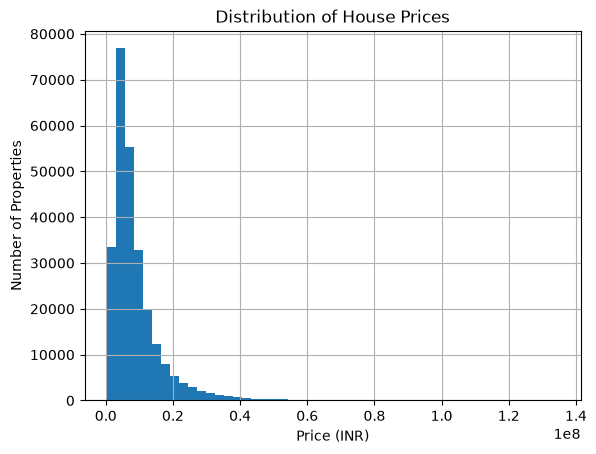

In [6]:
df['price_inr'].hist(bins= 50)
plt.xlabel('Price (INR)')
plt.ylabel('Number of Properties')
plt.title('Distribution of House Prices')
plt.show()

## Price by City Tier

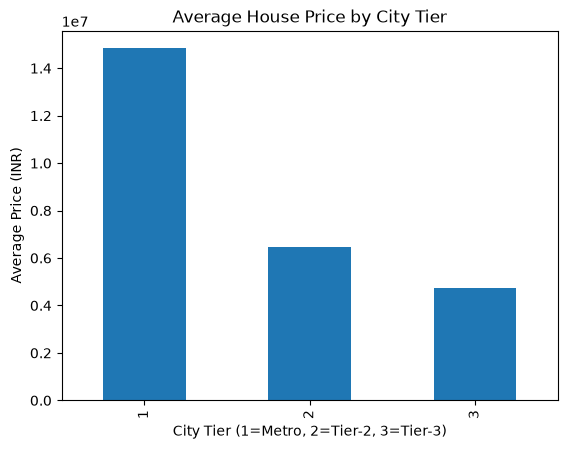

In [7]:
df.groupby('city_tier')['price_inr'].mean().plot(kind='bar')
plt.xlabel('City Tier (1=Metro, 2=Tier-2, 3=Tier-3)')
plt.ylabel('Average Price (INR)')
plt.title('Average House Price by City Tier')
plt.show()

## Price by Property Type

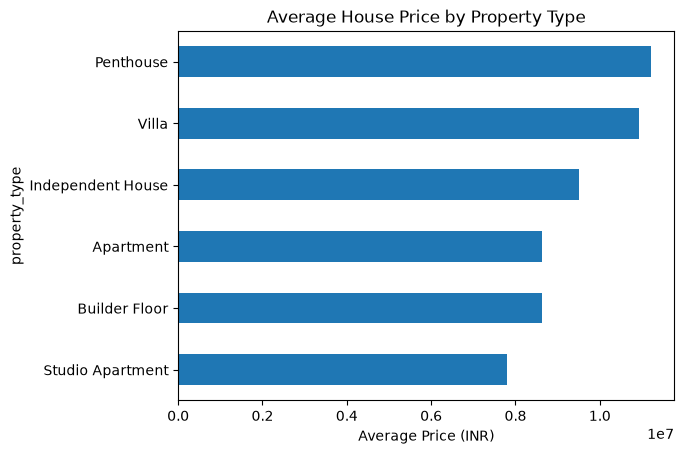

In [8]:
df.groupby('property_type')['price_inr'].mean().sort_values().plot(kind='barh')
plt.xlabel('Average Price (INR)')
plt.title('Average House Price by Property Type')
plt.show()

## Price vs. BHK (bedrooms)

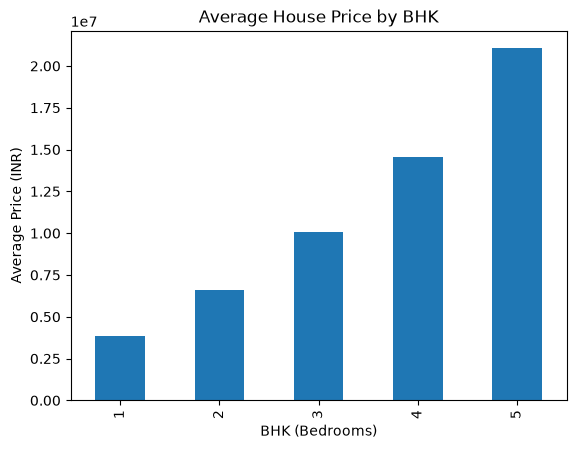

In [9]:
df.groupby('bhk')['price_inr'].mean().plot(kind='bar')
plt.xlabel('BHK (Bedrooms)')
plt.ylabel('Average Price (INR)')
plt.title('Average House Price by BHK')
plt.show()

## Check plot_area_sqft and fix it

In [10]:
# does this property have a plot area at all?
df['has_plot'] = df['plot_area_sqft'].notna().astype(int)           #True = 1, False = 0

print(df['has_plot'].value_counts())

has_plot
0    164648
1     95352
Name: count, dtype: int64


In [11]:
# Now fill the missing plot_area values with 0 (meaning "not applicable")
df['plot_area_sqft'] = df['plot_area_sqft'].fillna(0)

In [12]:
# Check 
print(df['plot_area_sqft'].isna().sum(), "missing values left")

0 missing values left


## Check distance_to_metro_km for which city have metro or not then fix

In [13]:
# Fill missing metro distance with -1 (a clear signal: "not applicable, city has no metro")
df['distance_to_metro_km'] = df['distance_to_metro_km'].fillna(-1)

In [14]:
print(df['distance_to_metro_km'].isna().sum(), "missing values left")

0 missing values left


In [15]:
print(df[df['city_has_metro'] == 0]['distance_to_metro_km'].unique()[:5])

[-1.]


## Convert listing_date to a real date type

In [16]:
df['listing_date'] = pd.to_datetime(df['listing_date'])

In [17]:
print(df['listing_date'].dtype)
print(df['listing_date'].min(), "to", df['listing_date'].max())

datetime64[us]
2022-01-01 00:00:00 to 2025-12-27 00:00:00


## Check for duplicate rows

In [18]:
print("Full duplicate rows:", df.duplicated().sum())

Full duplicate rows: 0


In [19]:
# Also check: are there duplicate property_ids (which should be impossible/unique)?
print("Duplicate property_id values:", df['property_id'].duplicated().sum())

Duplicate property_id values: 0


## Check for outliers / impossible values

In [20]:
# Carpet area should NEVER be bigger than super built-up area
impossible_area = (df['carpet_area_sqft'] > df['super_built_up_area_sqft']).sum()
print("Rows where carpet area > built-up area:", impossible_area)

Rows where carpet area > built-up area: 0


In [21]:
# Price per sqft should roughly match price_inr / super_built_up_area_sqft
check = (df['price_inr'] / df['super_built_up_area_sqft']).round(0)
mismatch = (abs(check - df['price_per_sqft']) > 1).sum()
print("Rows where price_per_sqft doesn't match price_inr/area:", mismatch)

Rows where price_per_sqft doesn't match price_inr/area: 0


In [22]:
# Any zero or negative prices/areas?
print("Zero or negative price_inr:", (df['price_inr'] <= 0).sum())
print("Zero or negative area:", (df['super_built_up_area_sqft'] <= 0).sum())

Zero or negative price_inr: 0
Zero or negative area: 0


## Save clean dataset

In [24]:
df.to_csv("../data/processed/india_house_prices_cleaned.csv", index=False)
print("Saved cleaned dataset:", df.shape)

Saved cleaned dataset: (260000, 58)


## Check correlation numeric features only (Heatmap & Price)

### Heatmap

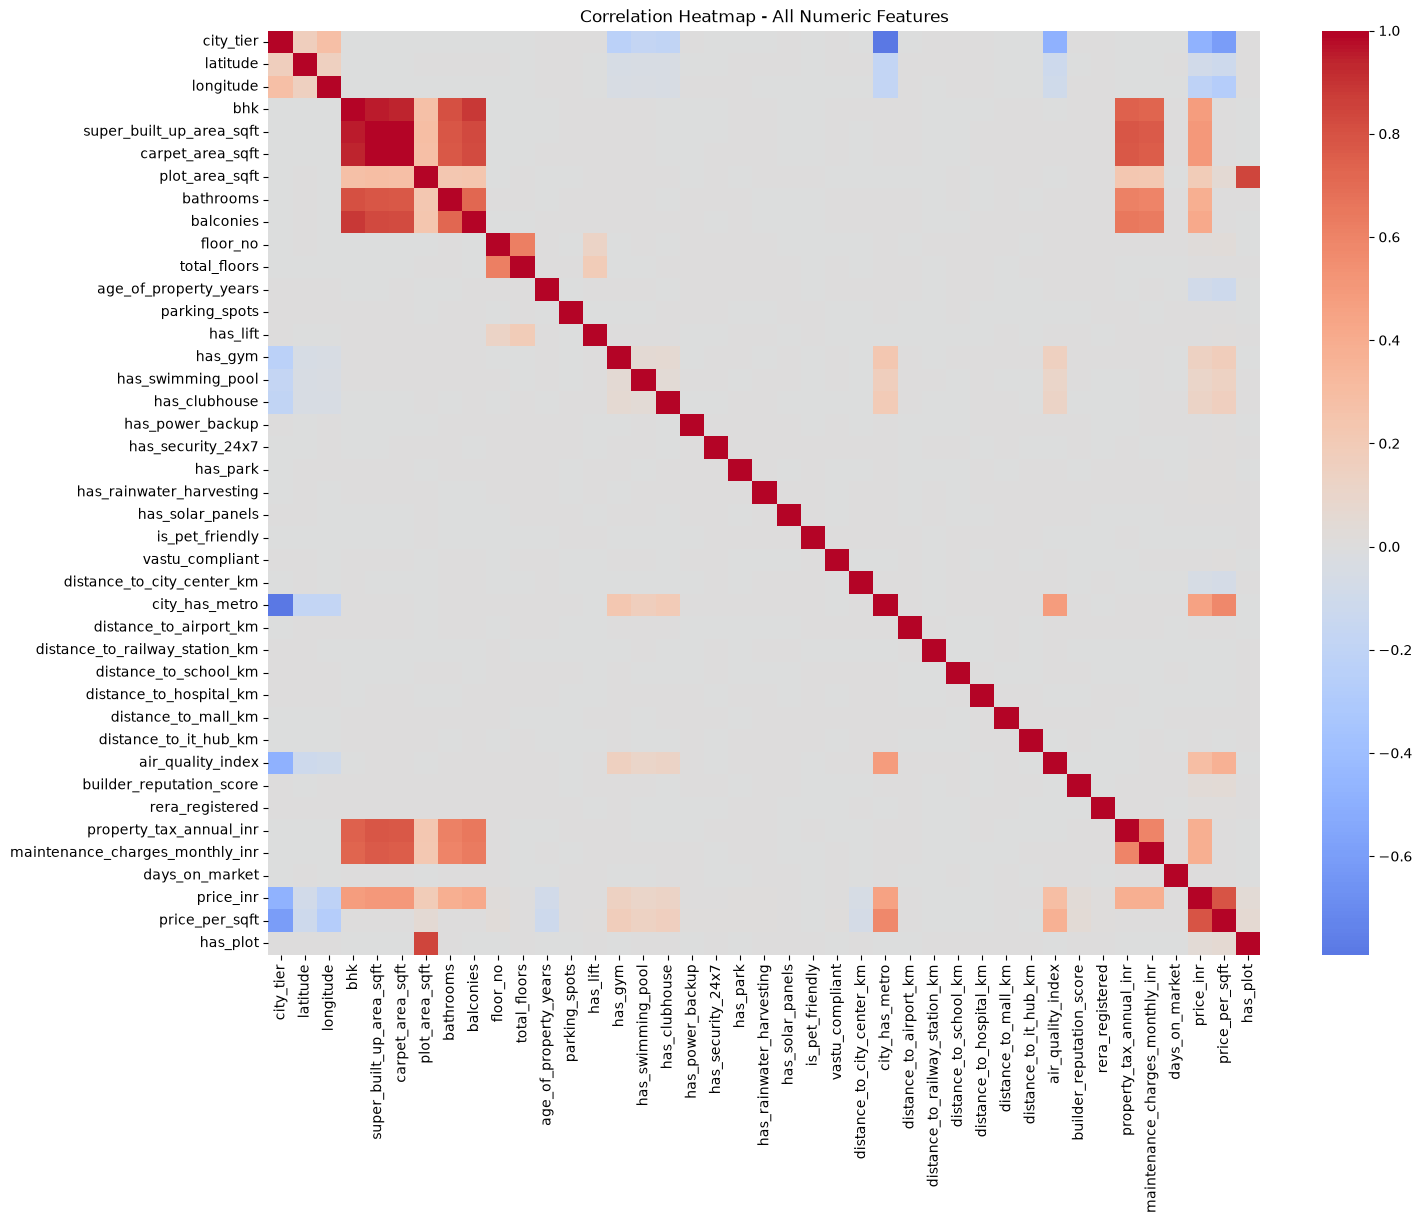

In [29]:
numeric_df = df.select_dtypes(include=['int64', 'float64']).drop(columns=['distance_to_metro_km'])
# dropped distance_to_metro_km here since it has placeholder -1 values that would distort this heatmap

plt.figure(figsize=(16, 12))
sns.heatmap(numeric_df.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Heatmap - All Numeric Features')
plt.show()

### Correlation with price

In [ ]:
# Close to +1 → as one goes up, the other goes up too
# Close to -1 → as one goes up, the other goes down
# Close to 0 → little to no relationship
correlations = numeric_df.corr()['price_inr'].sort_values(ascending=False)
print(correlations)

price_inr                          1.000000
price_per_sqft                     0.790918
super_built_up_area_sqft           0.501881
carpet_area_sqft                   0.497780
bhk                                0.477028
city_has_metro                     0.454766
balconies                          0.416146
property_tax_annual_inr            0.390923
bathrooms                          0.390432
maintenance_charges_monthly_inr    0.385644
air_quality_index                  0.289589
plot_area_sqft                     0.195360
has_gym                            0.144115
has_clubhouse                      0.121499
has_swimming_pool                  0.107665
has_plot                           0.045225
builder_reputation_score           0.036629
floor_no                           0.018946
rera_registered                    0.011844
has_park                           0.009570
has_rainwater_harvesting           0.008328
has_lift                           0.006363
has_power_backup                

In [26]:
metro_only = df[df['city_has_metro'] == 1]
print(metro_only[['distance_to_metro_km', 'price_inr']].corr())

                      distance_to_metro_km  price_inr
distance_to_metro_km              1.000000  -0.030885
price_inr                        -0.030885   1.000000


## Visualize two key relationships

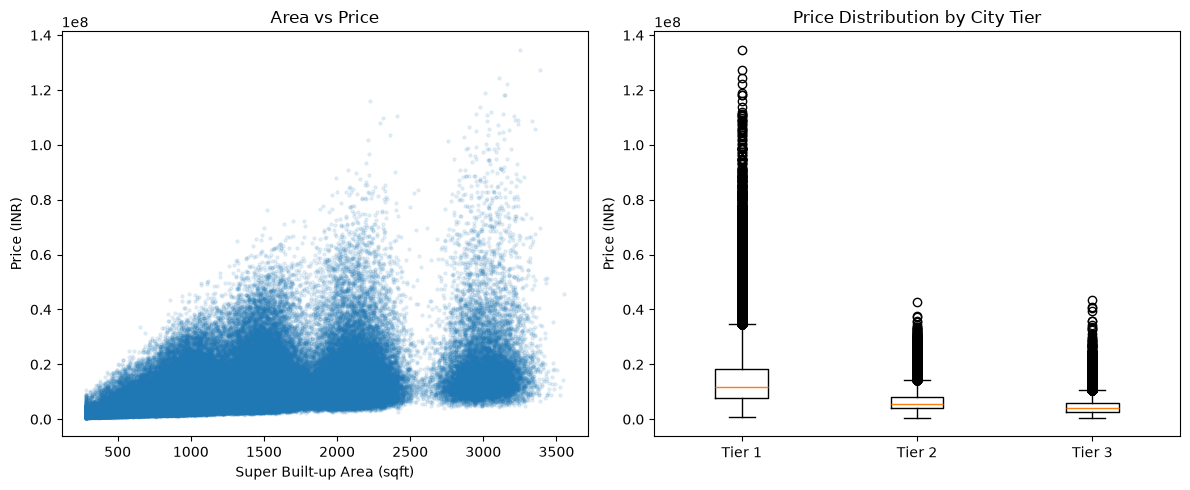

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(df['super_built_up_area_sqft'], df['price_inr'], alpha=0.1, s=5)
axes[0].set_xlabel('Super Built-up Area (sqft)')
axes[0].set_ylabel('Price (INR)')
axes[0].set_title('Area vs Price')

axes[1].boxplot([df[df['city_tier']==t]['price_inr'] for t in [1,2,3]], tick_labels=['Tier 1', 'Tier 2', 'Tier 3'])
axes[1].set_ylabel('Price (INR)')
axes[1].set_title('Price Distribution by City Tier')

plt.tight_layout()
plt.show()

## Check skewness of all numeric columns

In [ ]:
# Close to 0 → symmetric (good, no transformation needed)
# Above 1 or below -1 → noticeably skewed (may need transform)
skewness = numeric_df.skew().sort_values(ascending=False)
print(skewness)

price_inr                          3.292179
price_per_sqft                     2.501821
has_solar_panels                   2.348764
has_swimming_pool                  2.225928
distance_to_railway_station_km     1.920383
distance_to_city_center_km         1.903056
distance_to_school_km              1.892391
distance_to_hospital_km            1.836073
distance_to_mall_km                1.814646
distance_to_it_hub_km              1.782119
distance_to_airport_km             1.677476
plot_area_sqft                     1.592668
has_clubhouse                      1.378842
property_tax_annual_inr            1.317081
maintenance_charges_monthly_inr    1.312721
carpet_area_sqft                   1.018984
longitude                          1.004910
super_built_up_area_sqft           0.997669
has_gym                            0.958536
floor_no                           0.931478
has_plot                           0.553054
parking_spots                      0.512665
bathrooms                       

## Outlier detection using IQR

In [31]:
def count_outliers_iqr(column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return ((df[column] < lower) | (df[column] > upper)).sum()

for col in ['price_inr', 'super_built_up_area_sqft', 'age_of_property_years', 'distance_to_city_center_km']:
    print(col, ":", count_outliers_iqr(col), "outliers")

price_inr : 18364 outliers
super_built_up_area_sqft : 10330 outliers
age_of_property_years : 0 outliers
distance_to_city_center_km : 12297 outliers


## Price by categorical features

In [32]:
categorical_cols = ['furnishing_status', 'construction_status', 'water_supply', 'flood_risk_zone', 'seller_type', 'ownership_type', 'society_type']

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print(df.groupby(col)['price_inr'].mean().sort_values(ascending=False))


--- furnishing_status ---
furnishing_status
Furnished         9.839141e+06
Semi-Furnished    9.103709e+06
Unfurnished       8.647022e+06
Name: price_inr, dtype: float64

--- construction_status ---
construction_status
Ready to Move         9.253692e+06
Under Construction    8.376680e+06
Name: price_inr, dtype: float64

--- water_supply ---
water_supply
Both         9.056641e+06
Borewell     8.999084e+06
Municipal    8.982067e+06
Name: price_inr, dtype: float64

--- flood_risk_zone ---
flood_risk_zone
Medium    9.060358e+06
Low       8.998281e+06
High      8.928831e+06
Name: price_inr, dtype: float64

--- seller_type ---
seller_type
Owner      9.020240e+06
Builder    9.015834e+06
Agent      8.994450e+06
Name: price_inr, dtype: float64

--- ownership_type ---
ownership_type
Co-operative Society    9.060712e+06
Leasehold               9.034043e+06
Freehold                8.993815e+06
Name: price_inr, dtype: float64

--- society_type ---
society_type
Gated Society          9.024231e+06
St

## Price trend over time

In [33]:
df['listing_year'] = df['listing_date'].dt.year
print(df.groupby('listing_year')['price_inr'].mean())

listing_year
2022    8.924545e+06
2023    9.061500e+06
2024    9.028972e+06
2025    8.960081e+06
Name: price_inr, dtype: float64


## Combined amenity effect

In [35]:
amenity_cols = ['has_lift', 'has_gym', 'has_swimming_pool', 'has_clubhouse', 'has_power_backup',
                'has_security_24x7', 'has_park', 'has_rainwater_harvesting', 'has_solar_panels']

df['amenity_score'] = df[amenity_cols].sum(axis=1)

print(df.groupby('amenity_score')['price_inr'].mean())
print("\nCorrelation of amenity_score with price:", df['amenity_score'].corr(df['price_inr']))

amenity_score
0    6.975574e+06
1    7.373158e+06
2    7.742567e+06
3    8.144824e+06
4    8.700337e+06
5    9.705232e+06
6    1.096157e+07
7    1.243241e+07
8    1.380830e+07
9    1.678048e+07
Name: price_inr, dtype: float64

Correlation of amenity_score with price: 0.13092598095575092


## State and city-level patterns

In [36]:
print(df.groupby('state')['price_inr'].mean().sort_values(ascending=False).head(10))
print("\n")
print(df.groupby('city')['price_inr'].mean().sort_values(ascending=False).head(10))

state
Delhi          1.971562e+07
Maharashtra    1.614834e+07
Telangana      1.072433e+07
Goa            1.025118e+07
Karnataka      1.012752e+07
Chandigarh     9.705965e+06
Tamil Nadu     9.655135e+06
West Bengal    8.392470e+06
Kerala         7.387312e+06
Gujarat        7.244436e+06
Name: price_inr, dtype: float64


city
Mumbai        2.949195e+07
Delhi         1.971562e+07
Bangalore     1.434551e+07
Pune          1.279027e+07
Chennai       1.244957e+07
Hyderabad     1.184179e+07
Panaji        1.025118e+07
Kolkata       9.882362e+06
Chandigarh    9.705965e+06
Ahmedabad     8.277860e+06
Name: price_inr, dtype: float64
